# Fourier Transform

First explore classical Fourier transform, specially diecrete one (DFT).



The Discrete Fourier Transform (DFT) converts a signal from the time domain to the frequency domain. It helps analyze the frequency components in signals. 


Formula for DFT is given by

$$
y_k = \frac{1}{\sqrt{N}} \sum_{n=0}^{N-1} x_n e^{-i \frac{2\pi}{N} k n}
$$

In [9]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
# Implementing DFT using formula

def dft(x):
    N = len(x)
    X = np.zeros(N, dtype=complex)

    for k in range(N):
        for n in range(N):
            X[k] += x[n] * np.exp(-2j * np.pi * k * n / N)

    return X

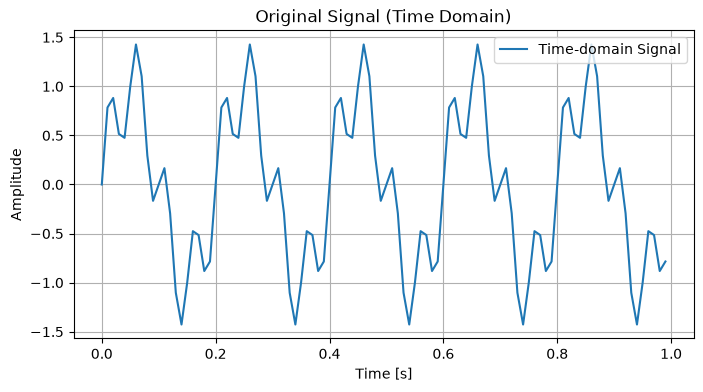

In [11]:
# Generate a sample signal

N = 100 
t = np.linspace(0, 1, N, endpoint=False)

# Generate a signal containing two frequencies (5 Hz and 20 Hz)
signal = np.sin(2 * np.pi * 5 * t) + 0.5 * np.sin(2 * np.pi * 20 * t)

# Plot the signal
plt.figure(figsize=(8, 4))
plt.plot(t, signal, label="Time-domain Signal")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("Original Signal (Time Domain)")
plt.legend()
plt.grid()
plt.show()

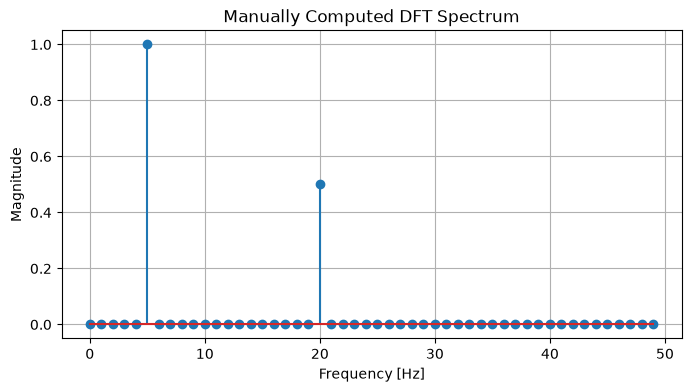

In [12]:
# Now apply our DFT function to transform the signal into the frequency domain

X_dft = dft(signal)
freqs = np.array([k for k in range(N)])

# Plot the magnitude spectrum 
plt.figure(figsize=(8, 4))
plt.stem(freqs[:N//2], np.abs(X_dft)[:N//2] / (N/2)) # Normalize magnitude
plt.xlabel("Frequency [Hz]")
plt.ylabel("Magnitude")
plt.title("Manually Computed DFT Spectrum")
plt.grid()
plt.show()

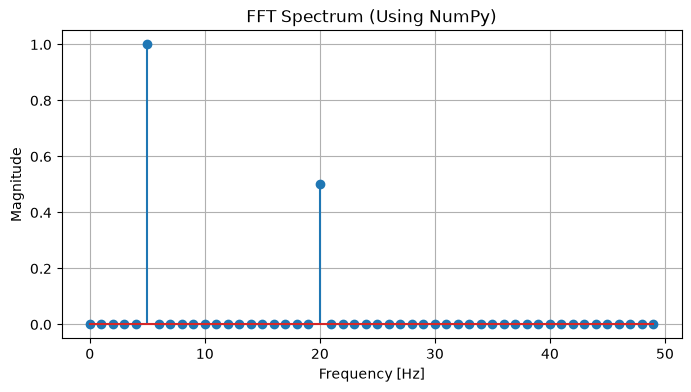

In [13]:
# Using Fast Fourier Transform (FFT)
X_fft = np.fft.fft(signal)

# Plot FFT spectrum
plt.figure(figsize=(8, 4))
plt.stem(freqs[:N//2], np.abs(X_fft)[:N//2] / (N/2)) # Normalize magnitude
plt.xlabel("Frequency [Hz]")
plt.ylabel("Magnitude")
plt.title("FFT Spectrum (Using NumPy)")
plt.grid()
plt.show()